# 02 — Exploratory Data Analysis (EDA)

Analyse descriptive, analyse du target, variables numériques/catégorielles, corrélation, feature engineering et sauvegarde du dataset.

## Imports

In [16]:
import pandas as pd
import numpy as np

# import matplotlib.pyplot as plt
# import seaborn as sns

# from sklearn.preprocessing import StandardScaler

# from sklearn.impute import KNNImputer


In [17]:
df = pd.read_csv("../data/raw/student_mental_health.csv")

print(df.shape)
df.head()

(2000, 17)


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## Determine the target and drop unessesary columns

In [18]:
# Remove identifier
df = df.drop(columns=["Student_ID"])

# Separate features and target
X = df.drop(columns=["Mental_Health_Risk"])
y = df["Mental_Health_Risk"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2000, 15)
Target shape: (2000,)


## Split data into train and test


In [19]:
from sklearn.model_selection import train_test_split


X_train , X_test, y_train ,y_test  = train_test_split(
    X , y , test_size = 0.2 , random_state = 42
)

## Missing Values (Imputation)


In [20]:
from sklearn.impute import SimpleImputer

# Identify column types
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)


# Numerical imputation
num_imputer = SimpleImputer(strategy="median")

# Categorical imputation
cat_imputer = SimpleImputer(strategy="most_frequent")

Numerical: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


/tmp/ipykernel_465097/3185797394.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


## Visualiser les outliers — Boxplots

ValueError: num must be an integer with 1 <= num <= 9, not 10

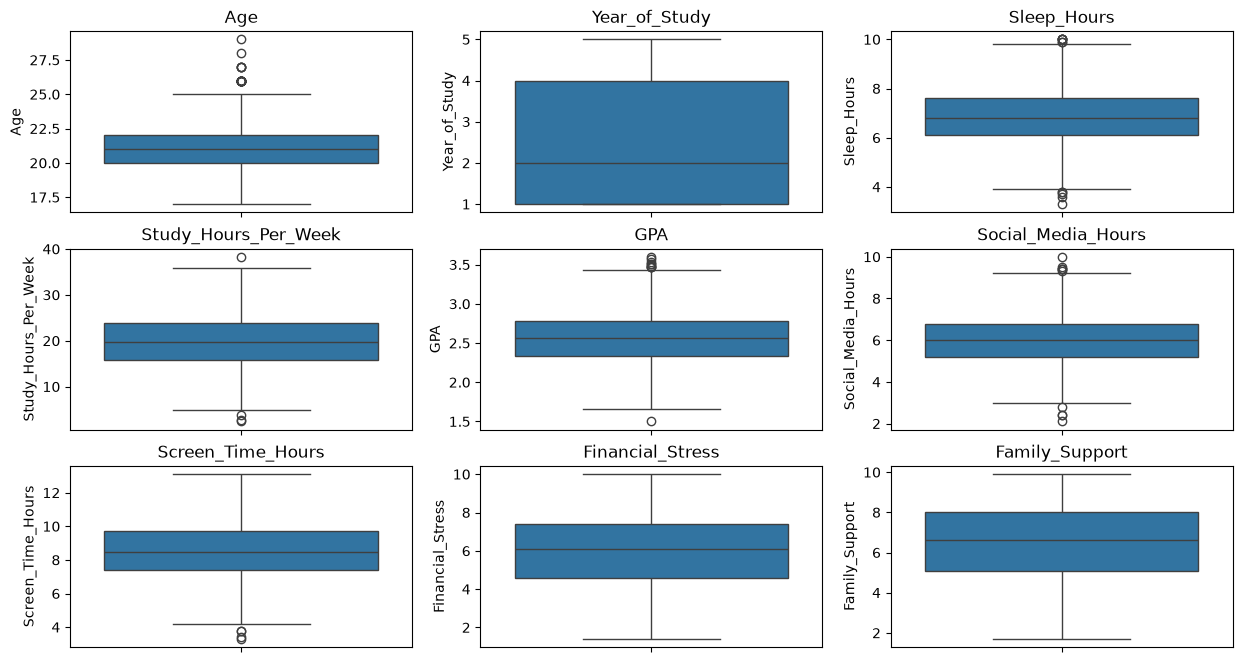

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

for i, col in enumerate(numeric_features):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=X_train[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [22]:
for col in numeric_features:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[col] < lower) |
        (X_train[col] > upper)
    ]

    print(col, ":", len(outliers))

Age : 33
Year_of_Study : 0
Sleep_Hours : 12
Study_Hours_Per_Week : 4
GPA : 10
Social_Media_Hours : 10
Screen_Time_Hours : 4
Financial_Stress : 0
Family_Support : 0
Attendance_Rate : 10


## Encoding Categorical Variables

In [23]:
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder
)

nominal_features = ["Gender"]

ordinal_features = [
    "Physical_Activity",
    "Diet_Quality"
]

binary_features = [
    "Part_Time_Job",
    "Previous_Mental_Health_History"
]
ordinal_categories = [
    ["Low", "Moderate", "High"],  # Physical Activity
    ["Poor", "Average", "Good"]   # Diet Quality
]

## Scaling Numerical Features

In [24]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

## Final Pipline


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

# Numerical Pipeline
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Nominal Pipeline
nominal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Binary Pipeline
binary_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="if_binary",
        handle_unknown="ignore"
    ))
])

# Ordinal Pipeline
ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[
            ["Low", "Moderate", "High"],
            ["Poor", "Average", "Good"]
        ],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("nom", nominal_pipeline, nominal_features),
        ("bin", binary_pipeline, binary_features),
        ("ord", ordinal_pipeline, ordinal_features)
    ],
    remainder="drop"
)

In [27]:

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using learned transformations
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (1600, 17)
Testing shape: (400, 17)


## Save Results

In [28]:
import joblib

joblib.dump(preprocessor, "../models/preprocessor.pkl")

import os

os.makedirs("../data/processed", exist_ok=True)

X_train.to_csv(
    "../data/processed/X_train.csv",
    index=False
)

X_test.to_csv(
    "../data/processed/X_test.csv",
    index=False
)

y_train.to_csv(
    "../data/processed/y_train.csv",
    index=False
)

y_test.to_csv(
    "../data/processed/y_test.csv",
    index=False
)

print("Train and Test datasets saved successfully!")

Train and Test datasets saved successfully!
